# Salarios formalidad y autoempleo ante los comentarios del coautor

Esta nota responde a la propuesta de concentrar el paper en salarios, formalidad y autoempleo, y de explorar una regresión discontinua por educación. Reestimamos los tres resultados con el diseño original y examinamos dos contrastes cerca del límite entre secundaria y educación superior. El DiD amplio muestra una caída relativa de la formalidad y un aumento del autoempleo, pero estas diferencias se atenúan en la comparación educativa más cercana. La información disponible no fundamenta una interpretación causal por regresión discontinua en ese límite.

**Cálculos en R.** Esta versión contiene celdas R nativas. Las celdas se ejecutaron secuencialmente con `Rscript` para guardar sus salidas; no se utilizó un kernel Jupyter en esta máquina. Para ejecución interactiva, seleccionar el kernel R (`IRkernel`). También se puede ejecutar `Rscript notebooks/feedback_coautor.R` desde `project/`. La base `data/processed/enaho_pooled.rds` debe estar disponible. Paquetes: `data.table`, `fixest`, `ggplot2`.

## Muestra y variables

Usamos cortes transversales repetidos de ENAHO entre 2021T1 y 2024T4, personas de 14 a 65 años con categoría educativa válida y ponderador positivo. Excluimos 2022T2 porque mezcla observaciones anteriores y posteriores al aumento de mayo. El período previo es 2021T1–2022T1 y el posterior 2022T3–2024T4. No seguimos a las mismas personas en el tiempo.

**Salario real por hora.** Logaritmo del salario horario en la ocupación principal entre asalariados privados con salario válido; incluye trabajadores del hogar. Se conserva la conversión de frecuencia de pago, el IPC del mes de referencia y la winsorización de la base original. No mide el ingreso de quienes salen del empleo asalariado.

**Formalidad.** Indicador de empleo formal entre ocupados no públicos. El coeficiente multiplicado por 100 expresa puntos porcentuales de esa proporción; no es la probabilidad de tener empleo formal en toda la población en edad de trabajar.

**Autoempleo.** Indicador de trabajador por cuenta propia, categoría p507 = 2, entre ocupados no públicos. Excluye empleadores. Formalidad y autoempleo no son categorías excluyentes: un trabajador por cuenta propia puede ser formal.

In [1]:
# Estimaciones solicitadas por el coautor. Ejecutar desde cualquier directorio:
# Rscript project/notebooks/feedback_coautor.R
suppressPackageStartupMessages({library(data.table); library(fixest); library(ggplot2)})
locate_root <- function() {
  scripts <- sub('^--file=', '', grep('^--file=', commandArgs(FALSE), value=TRUE))
  candidates <- c(Sys.getenv('MW_PROJ_ROOT'), getwd(), file.path(getwd(), 'project'),
                  dirname(getwd()), if (length(scripts)) dirname(dirname(scripts[1])))
  for (candidate in candidates[nzchar(candidates)]) {
    if (file.exists(file.path(candidate, 'data/processed/enaho_pooled.rds')))
      return(normalizePath(candidate))
  }
  stop('No se encontró enaho_pooled.rds. Defina MW_PROJ_ROOT con la ruta de project.')
}
root <- locate_root()
out <- file.path(root, 'notebooks')
d <- readRDS(file.path(root, 'data/processed/enaho_pooled.rds'))
d <- d[in_window == 1 & working_age == 1 & transition == 0 &
       educ_code %in% 1:11 & !is.na(region) & is.finite(fac500a) & fac500a > 0]
d[, did := low * post]
d[, above := as.integer(years_educ >= 13)]
d[, x := years_educ - 12]


cat("Observaciones de la muestra general:", nrow(d), "\n")
print(d[, .(n=.N), by=.(post, skill)][order(post, skill)])


Observaciones de la muestra general: 278064 
    post  skill      n
   <int> <char>  <int>
1:     0   High  27278
2:     0    Low  65954
3:     1   High  55816
4:     1    Low 129016


## Especificación principal

Sea L igual a uno para educación baja, hasta secundaria completa (p301a de 1 a 6), y cero para alguna educación superior (7 a 11). P indica el período posterior. Para cada uno de los tres resultados estimamos la ecuación (1). Z contiene edad, edad al cuadrado, sexo, estado civil y residencia urbana; E son los años imputados a la categoría educativa. Los efectos fijos se representan por α del departamento y λ del trimestre. No se agrega P por separado porque ya está absorbido por λ.

$$Y_{irt}=\alpha_r+\lambda_t+\beta L_i+\tau(L_iP_t)+Z_i^{\prime}\Gamma+\kappa E_i+\varepsilon_{irt}\tag{1}$$

El coeficiente τ es el cambio posterior menos previo del grupo con educación baja, relativo al cambio del grupo con educación alta, ajustado por controles. La razón para mantener esta especificación es concentrar la discusión en los tres resultados pedidos sin cambiar simultáneamente el diseño del paper. Su interpretación causal exigiría tendencias paralelas condicionales en ausencia de la reforma, ausencia de shocks diferenciales coincidentes y comparabilidad de las muestras. La educación alta es un grupo de comparación de menor exposición promedio, no un grupo con exposición garantizada igual a cero.

Todas las regresiones usan mínimos cuadrados ponderados por fac500a, efectos fijos de departamento y trimestre calendario, y errores estándar agrupados por departamento. Los efectos de trimestre absorben los cambios nacionales comunes; los de departamento, diferencias territoriales persistentes. La agrupación permite correlación de los errores dentro de cada departamento a lo largo del tiempo. Hay 25 grupos en las nueve estimaciones. Los intervalos y valores p usan la corrección de muestra finita de fixest y una distribución t con 24 grados de libertad. Esta inferencia no corrige sesgos de identificación.

## Comparación educativa cercana

La ecuación (2) restringe la muestra a secundaria completa (p301a = 6, 11 años imputados) y superior no universitaria incompleta (p301a = 7, 13 años). Conserva los controles Z, pesos y efectos fijos. No incluye E por separado porque, con solo esas dos categorías, E = 13 − 2L y es perfectamente colineal con la constante y L. La restricción pregunta si el patrón del DiD amplio también aparece entre grupos educativos más cercanos. τ local sigue siendo una diferencia en diferencias; requiere sus propias tendencias paralelas y no elimina la selección hacia la educación superior.

$$Y_{irt}=\alpha_r+\lambda_t+\beta L_i+\tau_{local}(L_iP_t)+Z_i^{\prime}\Gamma+\varepsilon_{irt}\tag{2}$$

## Exploración de la discontinuidad propuesta

Para explorar la sugerencia de RD fijamos c = 12 únicamente como punto intermedio entre las categorías de 11 y 13 años. Definimos x = E − 12 y A = 1(E ≥ 13). En la ecuación (3) usamos |x| ≤ 3, es decir, los valores imputados 9, 11, 13 y 14. Es la ventana simétrica entera más estrecha con al menos dos valores distintos por lado que permite estimar una pendiente a cada lado. No es un ancho de banda óptimo seleccionado por un estimador RD. Los 14 años agrupan superior no universitaria completa y universitaria incompleta.

$$\begin{aligned}Y_{irt}={}&\alpha_r+\lambda_t+\gamma A_i+b x_i+d(A_ix_i)\\&+q(P_tx_i)+h(A_iP_tx_i)+\theta(A_iP_t)+Z_i^{\prime}\Gamma+\varepsilon_{irt}\end{aligned}\tag{3}$$

La ecuación permite cuatro pendientes: una a cada lado del límite en cada período. γ es el salto alto menos bajo previo; γ + θ es el salto posterior, evaluados en x = 0. Reportamos −θ para que todos los cuadros mantengan la orientación educación baja menos alta. El cálculo extrapola sobre el intervalo sin observaciones entre 11 y 13 años y depende de la forma lineal y de la codificación de E.

El límite c = 12 lo introduce el análisis; no documentamos una regla de asignación de la RMV que cambie al cruzarlo. Una RD requiere un mecanismo de asignación al tratamiento que cambie en un umbral conocido. Tener una variable discreta no invalida toda RD, pero aquí se añade un soporte muy escaso y años imputados a categorías. Por eso la ecuación (3) es una diferencia descriptiva de saltos, no una RD causal ni una RD difusa con un primer estadio estimado. Véase Cattaneo y Titiunik (2022).

Referencia: [Cattaneo y Titiunik 2022, Regression Discontinuity Designs](https://rdpackages.github.io/references/Cattaneo-Titiunik_2022_ARE.pdf).

In [2]:
outcomes <- list(
  list(y='log_wage_hr', label='Log salario real por hora', filter=quote(wage_valid == 1)),
  list(y='formal', label='Empleo formal', filter=quote(employed == 1 & public_sector == 0 & !is.na(formal))),
  list(y='self_emp', label='Autoempleo', filter=quote(employed == 1 & public_sector == 0 & !is.na(self_emp)))
)
controls <- 'age + age2 + female + married + urban'
extract <- function(m, term, label, design, sample) {
  ct <- coeftable(m)[term, ]
  ci <- confint(m, parm=term, level=.95)
  data.table(diseno=design, muestra=sample, resultado=label, n=nobs(m),
    gl_t=degrees_freedom(m, type='t'),
    coef=unname(ct['Estimate']), ee=unname(ct['Std. Error']),
    p=unname(ct['Pr(>|t|)']),
    li95=unname(ci[1, 1]), ls95=unname(ci[1, 2]))
}
rows <- list()
models <- list()
for (o in outcomes) {
  s <- d[eval(o$filter)]
  # Diseño principal del paper, misma muestra y controles (incluye años de educación).
  f <- as.formula(sprintf('%s ~ did + low + %s + years_educ | t_index + region', o$y, controls))
  m <- feols(f, data=s, weights=~fac500a, cluster=~region, notes=FALSE)
  models[[paste(o$y, 'principal', sep='_')]] <- m
  rows[[length(rows)+1L]] <- extract(m, 'did', o$label, 'DiD principal: baja vs alta educación', 'Códigos 1–11')

  # Contraste inmediato al umbral: secundaria completa (11 años) vs superior
  # incompleta (13 años). El coeficiente se expresa como baja menos alta.
  near <- s[educ_code %in% 6:7]
  m2 <- feols(as.formula(sprintf('%s ~ did + low + %s | t_index + region', o$y, controls)),
              data=near, weights=~fac500a, cluster=~region, notes=FALSE)
  models[[paste(o$y, 'local', sep='_')]] <- m2
  rows[[length(rows)+1L]] <- extract(m2, 'did', o$label, 'DiD local: 11 vs 13 años', 'Códigos 6 y 7')

  # Diferencia de saltos descriptiva con tendencia lineal a cada lado del umbral.
  # Con pocos puntos de soporte, el salto en x=0 es extrapolado y no es una RD causal.
  wide <- s[abs(x) <= 3]
  f3 <- as.formula(sprintf('%s ~ above + x + above:x + post:x + post:above:x + above:post + %s | t_index + region', o$y, controls))
  m3 <- feols(f3, data=wide, weights=~fac500a, cluster=~region, notes=FALSE)
  models[[paste(o$y, 'salto', sep='_')]] <- m3
  r <- extract(m3, 'above:post', o$label, 'Cambio del salto lineal en 12 años', '9, 11, 13 y 14 años')
  # Orientar los tres diseños como baja menos alta.
  r[, c('coef','li95','ls95') := .(-coef, -ls95, -li95)]
  rows[[length(rows)+1L]] <- r
}
res <- rbindlist(rows)
fwrite(res, file.path(out, 'feedback_coautor_resultados.csv'))



## Resultados y unidades

Un coeficiente de −0,02065 en log salario equivale a una diferencia de aproximadamente −2,04% mediante 100(exp(τ)−1); no es una variación en soles. Los indicadores binarios se expresan en puntos porcentuales. Los coeficientes de los tres diseños están orientados como educación baja menos alta.

Los CSV conservan los coeficientes originales en logaritmos o proporciones. Esta tabla convierte solo formalidad y autoempleo a puntos porcentuales.

In [3]:
shown <- copy(res)
shown[, unidad := ifelse(resultado == "Log salario real por hora", "log puntos", "pp")]
for (v in c("coef", "ee", "li95", "ls95"))
  shown[unidad == "pp", (v) := get(v)*100]
print(shown[, .(diseno, resultado, n, unidad,
                coef=round(coef,4), ee=round(ee,4),
                li95=round(li95,4), ls95=round(ls95,4), p=signif(p,4))])


                                  diseno                 resultado      n     unidad    coef     ee    li95    ls95
                                  <char>                    <char>  <int>     <char>   <num>  <num>   <num>   <num>
1: DiD principal: baja vs alta educación Log salario real por hora  69534 log puntos -0.0206 0.0123 -0.0460  0.0047
2:              DiD local: 11 vs 13 años Log salario real por hora  29008 log puntos -0.0246 0.0237 -0.0736  0.0243
3:    Cambio del salto lineal en 12 años Log salario real por hora  51072 log puntos -0.0498 0.0458 -0.1443  0.0447
4: DiD principal: baja vs alta educación             Empleo formal 181317         pp -4.6420 0.7391 -6.1675 -3.1166
5:              DiD local: 11 vs 13 años             Empleo formal  64143         pp -1.4030 1.2259 -3.9331  1.1271
6:    Cambio del salto lineal en 12 años             Empleo formal 117450         pp  1.1233 2.2115 -3.4410  5.6876
7: DiD principal: baja vs alta educación                Autoempleo 18131

La estimación amplia de salarios es imprecisa al 5%: su intervalo va aproximadamente de −4,50% a +0,47%. No equivale a demostrar ausencia de efecto. La formalidad y el autoempleo presentan asociaciones diferenciales en el DiD amplio. La comparación local reduce sus magnitudes y ofrece intervalos más amplios; el cambio del salto lineal tampoco se distingue de cero. Cambiar de muestra cambia la población comparada: la falta de significación local no es una prueba de que los coeficientes amplios y locales difieran estadísticamente.

## Diagnóstico de exposición previo a la reforma

Como diagnóstico descriptivo, calculamos la fracción ponderada de asalariados privados bajo la RMV en el período previo. Es 37,63% para secundaria completa y 37,35% para superior no universitaria incompleta, una diferencia de 0,29 puntos porcentuales. Las medias son muy parecidas, pero no constituyen una prueba formal de ausencia de discontinuidad. Estar bajo la RMV tampoco equivale a recibir el tratamiento: intervienen horas trabajadas, cumplimiento y cobertura. Este gráfico no sirve para dividir el efecto de resultados por un supuesto primer estadio.

In [4]:
# Diagnóstico descriptivo de exposición: fracción de asalariados privados bajo
# la RMV antes de la reforma. No es un primer estadio de tratamiento ni una
# prueba formal de discontinuidad; bajo la RMV no equivale a estar afectado.
pre <- d[post == 0 & wage_valid == 1 & !is.na(below_mw)]
support <- pre[, .(n=.N, peso=sum(fac500a),
                   pct_bajo_rmv=weighted.mean(below_mw, fac500a),
                   salario_hora=weighted.mean(wage_hr_real, fac500a)),
               by=.(educ_code, years_educ)][order(years_educ, educ_code)]
fwrite(support, file.path(out, 'feedback_coautor_soporte.csv'))

# Medias por categoría y período, útiles para examinar la extrapolación local.
means <- rbindlist(lapply(outcomes, function(o) {
  s <- d[eval(o$filter)]
  z <- s[, .(n=.N, media=weighted.mean(get(o$y), fac500a)),
    by=.(educ_code, years_educ, post)]
  z[, resultado := o$label]
  z
}))
fwrite(means, file.path(out, 'feedback_coautor_medias.csv'))


print(support)


    educ_code years_educ     n        peso pct_bajo_rmv salario_hora
        <num>      <num> <int>       <num>        <num>        <num>
 1:         1          0   254   61411.686   0.75281069     4.371153
 2:         2          1    12    3652.304   0.43983376     5.829633
 3:         3          3  1559  453062.043   0.59358041     5.366775
 4:         4          6  1756  548999.197   0.54867843     5.496107
 5:         5          9  3317 1085103.401   0.53603776     5.410399
 6:         6         11  7551 3022819.620   0.37632478     6.093738
 7:         7         13  1453  596627.352   0.37347171     6.577044
 8:         8         14  2314  922882.630   0.22864003     7.578434
 9:         9         14  1626  626540.379   0.36085447     7.429829
10:        10         16  2149  799669.890   0.12162261    12.874894
11:        11         18   253   75666.223   0.04426825    28.038031


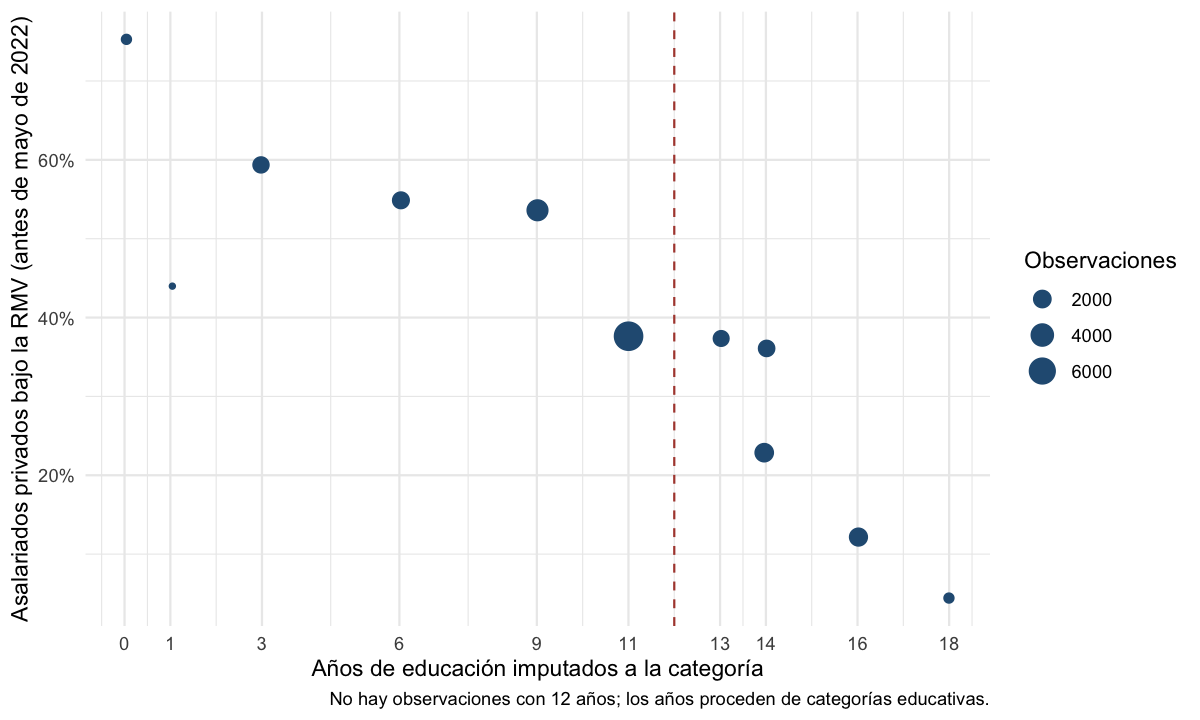

In [5]:
set.seed(42)
p <- ggplot(support, aes(years_educ, pct_bajo_rmv)) +
  geom_point(aes(size=n), color='#275b82',
             position=position_jitter(width=0.05, height=0, seed=42)) +
  geom_vline(xintercept=12, linetype='dashed', color='#af473c') +
  scale_x_continuous(breaks=sort(unique(support$years_educ))) +
  scale_y_continuous(labels=function(x) sprintf('%.0f%%', 100*x)) +
  labs(x='Años de educación imputados a la categoría',
       y='Asalariados privados bajo la RMV (antes de mayo de 2022)',
       size='Observaciones',
       caption='No hay observaciones con 12 años; los años proceden de categorías educativas.') +
  theme_minimal(base_size=11)
ggsave(file.path(out, 'feedback_coautor_exposicion.png'), p, width=8, height=4.8, dpi=150)


print(p)


## Reservas que deben acompañar los tres resultados

El archivo de tendencias previas del paper rechaza la igualdad conjunta de los coeficientes anteriores a la reforma para salarios (p = 0,0013) y autoempleo (p = 0,0031); para formalidad p = 0,148. No rechazar en formalidad no demuestra tendencias paralelas, y estos diagnósticos del DiD amplio no validan automáticamente las muestras locales.

La medición de formalidad utiliza el indicador oficial cuando está disponible y una reconstrucción en 2024. La comparación temporal hereda esa limitación. Los salarios y los dos indicadores de composición se condicionan en la ocupación observada, que también puede cambiar tras la reforma.

Las caídas de formalidad y aumentos de autoempleo son cambios en proporciones de cortes transversales. No demuestran que las mismas personas abandonaron un empleo formal para convertirse en independientes. Para esa afirmación harían falta transiciones individuales identificadas.

Como antecedente ya existente, la validación de la reforma de 2025 reporta autoempleo de signo opuesto (−1,43 puntos; p = 0,026). No añadimos una nueva batería de robustez: retenemos estas reservas porque afectan la interpretación de los tres resultados centrales.

## Síntesis para que el coautor redacte

Al concentrar el análisis en salarios, formalidad y autoempleo, el DiD principal estima una variación relativa de −0,021 log puntos en el salario horario real (p = 0,106), una reducción de 4,64 puntos porcentuales en formalidad y un aumento de 3,63 puntos en autoempleo (ambos p < 0,001). En la comparación entre secundaria completa y superior no universitaria incompleta, las estimaciones son −0,025 log puntos, −1,40 y +1,30 puntos porcentuales, respectivamente, y sus intervalos al 95% incluyen cero. La comparación local no confirma con precisión el patrón amplio, pero tampoco prueba efectos nulos. La propuesta de discontinuidad queda como ejercicio exploratorio, porque el límite educativo utilizado no corresponde a una regla de asignación de la reforma. Las tendencias previas y la composición de las muestras requieren prudencia al atribuir los cambios a la RMV.

## Revisión y trazabilidad

Las nueve regresiones se contrastaron con `lm()` y una matriz de covarianza agrupada calculada a partir de los residuos y la matriz de diseño, sin reutilizar la matriz de covarianza de `fixest`. Los coeficientes y errores estándar difieren menos de 1e−9; los valores p menos de 1e−8. Las tres filas principales coinciden con `output/main_did_coefs.csv`. Se verificaron también el número de observaciones, los 25 departamentos, los signos y los intervalos.

La auditoría es `revisar_feedback_coautor.R`; sus resultados son `feedback_coautor_revision.csv`. `feedback_coautor_sesion.txt` registra versiones y el hash de la base. Los diagnósticos heredados provienen de `output/pretrend_tests.csv` y `output/validation2025_did.csv`. Para repetir la auditoría, ejecutar `Rscript notebooks/revisar_feedback_coautor.R` desde `project/`.

La réplica numérica comprueba los cálculos; no certifica los supuestos causales ni revalida toda la construcción de los microdatos.